<a href="https://colab.research.google.com/github/fccampelo/transito-saopaulo/blob/main/cd_projeto_aplicado_IV_doc.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

  <img src="https://raw.githubusercontent.com/scalabrinig/cdProjetoAplicadoIV/d093146488f56dfcf0ef286bcee8efe0e71b9c76/figuras/mackenzie_logo.jpg" width="25%" align="right"/>

# **PROJETO APLICADO IV - Ciência de Dados EaD - 2026/02**


# **Documentação do Projeto**

---

# **Título do Projeto**

**Segurança viária orientada a dados: análise e modelagem dos fatores associados a sinistros de trânsito fatais no Estado de São Paulo**

GitHub: https://github.com/fccampelo/transito-saopaulo

---

In [ ]:
#@title **Identificação do Grupo**

#@markdown Integrantes do Grupo, nome completo em ordem alfabética (*informe: \<nome\>, \<matrícula\>*)
Aluno1 = 'Felipe Carlos Campelo, 10730758' #@param {type:"string"}



# **Resumo**

Os sinistros de trânsito matam cerca de 1,19 milhão de pessoas por ano no mundo, e o Brasil assumiu, no âmbito da Década de Ação pela Segurança no Trânsito 2021–2030 e do ODS 3.6, a meta de reduzir essas mortes em 50%. No Estado de São Paulo, os microdados do Infosiga SP registram centenas de milhares de ocorrências, mas seu uso ainda é predominantemente descritivo. Este projeto propõe um produto analítico que (i) identifica, por meio de modelos de classificação interpretáveis (regressão logística como linha de base e algoritmos baseados em árvores, explicados com valores SHAP), as características do sinistro, da via, do momento, dos veículos e das vítimas associadas ao desfecho fatal, e (ii) modela a série temporal mensal de óbitos (SARIMA, Prophet e modelos com defasagens) para projetar sua evolução frente à meta de 2030. Espera-se entregar fatores de risco e padrões espaciais de letalidade que apoiem a priorização de ações de segurança viária por gestores públicos. *(Resumo preliminar: será atualizado com os principais resultados na entrega final.)*

# **Introdução**

## Contexto

A segurança viária é um dos campos em que decisões de política pública produzem efeitos diretos, imediatos e mensuráveis sobre a vida das pessoas. De acordo com a Organização Mundial da Saúde, aproximadamente 1,19 milhão de pessoas morrem todos os anos em decorrência de sinistros de trânsito no mundo, o que faz dessas ocorrências a principal causa de morte entre crianças e jovens de 5 a 29 anos. Mais da metade dessas mortes atinge usuários vulneráveis das vias, isto é, pedestres, ciclistas e motociclistas, e a maior parte delas é considerada evitável mediante intervenções já conhecidas (WORLD HEALTH ORGANIZATION, 2023). Foi nesse contexto que a Assembleia Geral das Nações Unidas instituiu a Década de Ação pela Segurança no Trânsito 2021–2030, que estabelece a meta de reduzir em pelo menos 50% o número de mortes e lesões no trânsito até 2030.

O presente projeto se insere na área de conhecimento da ciência de dados aplicada à mobilidade urbana e à saúde pública. Trata-se de um domínio essencialmente interdisciplinar, no qual técnicas de análise exploratória, aprendizado de máquina supervisionado, análise de séries temporais, análise espacial e visualização de dados são combinadas com conceitos de engenharia de tráfego e de epidemiologia das causas externas. Nos últimos anos, por exemplo, o aumento do número de motocicletas mudou o perfil das vítimas nas cidades paulistas, e entender esse tipo de mudança exige analisar grandes volumes de registros administrativos.

No Estado de São Paulo, esses registros são consolidados pelo Sistema de Informações Gerenciais de Sinistros de Trânsito, o Infosiga SP, mantido pelo Departamento Estadual de Trânsito (Detran-SP). O sistema integra informações provenientes da Polícia Civil, da Polícia Militar, do Corpo de Bombeiros e das bases de veículos e condutores do próprio Detran, cobrindo os 645 municípios paulistas, e disponibiliza os microdados correspondentes em formato aberto (SÃO PAULO, 2026). Os números publicados evidenciam a dimensão do problema: somente em 2024 foram registrados 135.545 sinistros de trânsito no estado (MOBILIDADE SAMPA, 2025). Na capital, 2025 encerrou com 1.034 óbitos, o segundo maior resultado da série histórica iniciada em 2015, sendo 475 motociclistas e 410 pedestres, com forte concentração entre homens e nas faixas etárias de 20 a 29 anos (AGÊNCIA BRASIL, 2026).

Apesar da qualidade e da abrangência dessa base, o uso predominante que dela se faz ainda é descritivo: painéis, boletins mensais e comparações de totais entre períodos. Esse tipo de leitura responde à pergunta sobre quanto aconteceu, mas não sobre quais combinações de condições tornam um sinistro mais letal, nem sobre onde e quando essas combinações se repetem, nem sobre a trajetória esperada dos óbitos nos próximos anos. Gestores municipais e órgãos estaduais, que operam com orçamento e efetivo limitados, precisam justamente dessa informação para escolher entre alternativas concorrentes de intervenção, como fiscalização de velocidade, redesenho de cruzamentos, sinalização, campanhas educativas ou tratamento de trechos específicos.

O problema selecionado pode ser enunciado da seguinte forma: quais características do sinistro, da via, do momento da ocorrência, dos veículos envolvidos e do perfil das vítimas estão mais fortemente associadas ao desfecho fatal no trânsito do Estado de São Paulo, em que medida essas características permitem estimar a probabilidade de que um sinistro resulte em morte e qual a trajetória projetada dos óbitos ao longo do tempo? Trata-se, portanto, de um problema de classificação supervisionada com forte desbalanceamento de classes, complementado por um problema de previsão de séries temporais e por um componente descritivo e espacial que identifica onde os padrões de risco se concentram.

## Motivação e Justificativa

A primeira justificativa do projeto é a relevância social do tema. Diferentemente de outros fenômenos analisados por meio de dados, a morte no trânsito é amplamente evitável e existe consenso técnico internacional sobre a eficácia de intervenções específicas. A meta assumida pelo Brasil no âmbito da Década de Ação pela Segurança no Trânsito e do Objetivo de Desenvolvimento Sustentável 3.6 pressupõe capacidade de diagnóstico local: sem identificar quais fatores concentram a letalidade em cada contexto, a redução de 50% até 2030 permanece uma intenção sem plano de execução (WORLD HEALTH ORGANIZATION, 2023).

A segunda justificativa é a existência de dados públicos, oficiais e com granularidade suficiente para sustentar uma análise consistente. O conjunto Sinistros (Infosiga) é publicado sob licença Creative Commons Attribution 4.0, com atualização mensal e dicionário de dados próprio, o que garante ao mesmo tempo viabilidade técnica, reprodutibilidade dos resultados e legitimidade das conclusões (SÃO PAULO, 2026). A série disponível cobre óbitos desde 2015 e sinistros não fatais desde 2019, período longo o bastante para captar tendências, sazonalidades e mudanças de perfil das vítimas, e não apenas variações conjunturais.

A terceira justificativa é o potencial de aplicabilidade do produto analítico. Os resultados esperados podem ser utilizados por prefeituras na priorização de trechos e horários para fiscalização e engenharia de tráfego, pelo Detran-SP e por concessionárias de rodovias no direcionamento de campanhas segmentadas por modal e perfil de usuário, e por pesquisadores e imprensa como referência para o acompanhamento das metas estaduais. Um modelo interpretável, que explicite o peso de cada fator, é mais útil nesse cenário do que um modelo apenas acurado, porque a decisão pública precisa ser justificada e comunicada (LUNDBERG; LEE, 2017).

Há, por fim, o interesse formativo. O conjunto escolhido exige o percurso completo de um projeto de ciência de dados: integração de três tabelas relacionadas com granularidades diferentes, tratamento de inconsistências e de revisões retroativas dos registros, engenharia de atributos temporais e espaciais, modelagem com classes desbalanceadas, modelagem de séries temporais, avaliação por métricas adequadas a esses cenários e comunicação dos achados para um público não técnico. Esse percurso será conduzido segundo as fases do modelo de referência CRISP-DM, que estrutura o trabalho desde o entendimento do negócio até a implantação (WIRTH; HIPP, 2000).

**Vínculo com os ODS e caráter extensionista:** o projeto se vincula ao ODS 3 (Saúde e Bem-Estar), meta 3.6, e ao ODS 11 (Cidades e Comunidades Sustentáveis), meta 11.2. A contribuição à sociedade se dá pela publicação aberta do código, da documentação e dos resultados no GitHub.

## Objetivos

### Objetivo geral

Desenvolver um produto analítico, baseado nos microdados públicos do Infosiga SP, capaz de caracterizar e modelar os fatores associados à ocorrência de sinistros de trânsito com vítimas fatais no Estado de São Paulo e de projetar a evolução temporal dos óbitos, de modo a apoiar a priorização de ações de segurança viária por gestores públicos.

### Objetivos específicos

a) integrar as tabelas de sinistros, vítimas e veículos em uma base analítica única, preservando a rastreabilidade entre os diferentes níveis de granularidade;

b) tratar valores ausentes, inconsistências de preenchimento e registros revisados retroativamente, documentando de forma explícita todos os critérios adotados;

c) realizar análise exploratória sob três recortes complementares: temporal (ano, mês, dia da semana e turno), espacial (município, região administrativa e tipo de via) e de perfil (modal, posição da vítima, sexo e faixa etária);

d) construir atributos derivados relevantes para o problema, tais como turno da ocorrência, indicador de fim de semana e feriado, categoria de via e modal predominante no sinistro;

e) treinar e comparar modelos de classificação para o desfecho fatal, adotando a regressão logística como linha de base e algoritmos baseados em árvores como alternativa, avaliados por métricas apropriadas a classes desbalanceadas, como a área sob a curva de precisão e revocação (HASTIE; TIBSHIRANI; FRIEDMAN, 2009);

f) construir a série temporal mensal de óbitos, decompô-la em tendência e sazonalidade e comparar modelos de previsão (sazonal ingênuo, SARIMA, Prophet e modelos com defasagens), projetando a trajetória dos óbitos frente à meta de redução de 50% até 2030;

g) interpretar os modelos obtidos, traduzindo coeficientes e medidas de importância de atributos em fatores de risco compreensíveis por gestores públicos;

h) identificar a concentração espacial das ocorrências fatais, destacando municípios e tipos de via com maior letalidade relativa;

i) consolidar os achados em um relatório final e em visualizações que sustentem a narrativa dos dados.

## Descrição da base de dados

### Fonte, forma e período de coleta

O conjunto de dados escolhido é o Sinistros (Infosiga), publicado pelo Departamento Estadual de Trânsito de São Paulo, por meio de sua Diretoria de Segurança Viária, no Portal de Dados Abertos do Estado de São Paulo. Os dados não são coletados especificamente para fins de pesquisa: eles resultam da integração de registros administrativos produzidos por boletins de ocorrência da Polícia Civil e da Polícia Militar, por atendimentos do Corpo de Bombeiros e pelo cruzamento com as bases de veículos e condutores do Detran-SP. Essa origem tem uma implicação metodológica importante, pois linhas já publicadas podem ser revisadas em atualizações posteriores, à medida que os órgãos fornecedores complementam ou corrigem as informações (SÃO PAULO, 2026).

A consolidação é mensal e ocorre por volta do dia 15 do mês subsequente ao de referência. A série histórica de vítimas fatais tem início em 2015; os sinistros não fatais passaram a ser registrados a partir de 2019, com a evolução do sistema, que se encontra atualmente em sua versão 3.0 (MOBILIDADE SAMPA, 2025). A cobertura é estadual e alcança os 645 municípios paulistas, incluindo vias municipais, rodovias estaduais e rodovias federais que cortam o território do estado. A ficha técnica e a abrangência da fonte estão sintetizadas no Quadro 1.

**Quadro 1 — Ficha técnica do conjunto de dados**

| | |
|---|---|
| **Nome** | Sinistros (Infosiga) — Eventos, Vítimas e Veículos envolvidos em Sinistros de Trânsito |
| **Órgão responsável** | Detran-SP — Diretoria de Segurança Viária |
| **Publicação** | Portal de Dados Abertos do Estado de São Paulo |
| **Cobertura** | Estado de São Paulo, 645 municípios |
| **Período** | Vítimas fatais desde 2015; sinistros não fatais desde 2019 |
| **Atualização** | Mensal, por volta do dia 15 do mês subsequente |
| **Formato** | Arquivo ZIP contendo arquivos CSV, com dicionário de dados publicado à parte |
| **Licença** | Creative Commons Attribution 4.0 |

Fonte: elaborado pelo autor a partir de São Paulo (2026).

### Estrutura e organização

Os dados são distribuídos em um único arquivo compactado que reúne três arquivos CSV distintos, correspondentes a três níveis de análise relacionados entre si: sinistros, que descreve o evento; vítimas (pessoas), que descreve as pessoas envolvidas; e veículos, que descreve os veículos envolvidos. Cada arquivo possui, portanto, granularidade própria, com uma linha por evento, por vítima e por veículo, respectivamente, ligadas pela chave `id_sinistro` (e por `id_veiculo`, entre vítimas e veículos). Os arquivos são publicados em séries por período (2015–2021, 2022–2024 e 2025 em diante), o que exige a concatenação prévia das séries e a verificação da compatibilidade dos campos entre elas.

Essa organização relacional é uma das razões da escolha do conjunto, pois permite análises em diferentes recortes. É possível, por exemplo, tratar o sinistro como unidade e classificar seu desfecho, tratar a vítima como unidade e estudar a gravidade da lesão em função do modal e da posição ocupada no veículo, ou agregar os óbitos por mês para formar uma série temporal. O Quadro 2 resume as principais informações disponíveis em cada arquivo.

**Quadro 2 — Principais informações disponíveis por arquivo**

| Arquivo | Principais campos |
|---|---|
| **Sinistros** | Data, hora, dia da semana e turno da ocorrência; município e código IBGE; região administrativa; logradouro; latitude e longitude; tipo de via (municipal, estadual ou federal); circunscrição da via; responsável pela administração e pela conservação da via; tipo de sinistro primário (colisão frontal, lateral, transversal ou traseira, atropelamento, capotamento, tombamento, choque e engavetamento); gravidade da ocorrência; tipo de registro; ocorrência em local público ou privado. |
| **Vítimas** | Sexo e idade da vítima; faixa etária demográfica e legal; nacionalidade; profissão; grau de instrução; meio de locomoção da vítima; posição ocupada no momento do sinistro; gravidade da lesão (fatal, grave, leve ou ileso); data e local do óbito; tempo em dias entre o sinistro e o óbito. |
| **Veículos** | Tipo do veículo (automóvel, motocicleta, caminhão, ônibus e bicicleta, entre outros); marca e modelo; cor; ano de fabricação; ano-modelo. |

Fonte: elaborado pelo autor a partir do dicionário de dados do Infosiga SP (SÃO PAULO, 2026).

### Volume e natureza das variáveis

O volume é compatível com a proposta do projeto e superior ao de bases utilizadas em exercícios acadêmicos convencionais. Considerando que apenas o ano de 2024 concentrou 135.545 sinistros no estado, a série completa acumula centenas de milhares de eventos e um número ainda maior de registros nos arquivos de vítimas e de veículos, uma vez que um mesmo sinistro pode envolver diversas pessoas e veículos (MOBILIDADE SAMPA, 2025). Os nove arquivos CSV extraídos somam aproximadamente 930 MB.

Quanto à natureza, predominam variáveis categóricas nominais, como tipo de sinistro, tipo de via e modal, o que exigirá estratégias adequadas de codificação antes da modelagem. Há também variáveis temporais, que permitem a construção de atributos derivados de sazonalidade e a agregação em séries mensais; variáveis geográficas contínuas, na forma de latitude e longitude, que viabilizam a análise espacial; e um número reduzido de variáveis numéricas, como idade da vítima, ano de fabricação do veículo e tempo em dias entre o sinistro e o óbito. A variável-alvo do problema de classificação será construída a partir da gravidade registrada, resultando em um indicador binário de desfecho fatal; a variável-alvo do problema de previsão será o número mensal de óbitos.

### Limitações e aspectos éticos

Três limitações precisam ser explicitadas desde o início. A primeira é a revisão retroativa dos registros, já mencionada, que torna necessário fixar uma versão de referência da base e registrar a data de extração para assegurar a reprodutibilidade dos resultados. A segunda é a descontinuidade metodológica de 2019, quando os sinistros não fatais passaram a ser registrados, o que impede a comparação direta de totais absolutos entre os períodos anterior e posterior a essa mudança; por isso, a série temporal de previsão utilizará apenas os óbitos, registrados de forma consistente desde 2015. A terceira é o preenchimento incompleto de determinados campos, particularmente os de caráter socioeconômico da vítima, como profissão e grau de instrução, e o georreferenciamento ausente em parte das ocorrências, o que restringirá o uso dessas variáveis a análises complementares.

Do ponto de vista ético e legal, os microdados são publicados de forma anonimizada, sem qualquer elemento que permita a identificação nominal das vítimas, e sob licença que autoriza expressamente a reutilização mediante atribuição da fonte. O tratamento previsto neste projeto é agregado e não busca, em nenhuma etapa, a reidentificação de indivíduos, em conformidade com a finalidade estatística e de interesse público que motivou a publicação da base.

# **Referencial Teórico**

O projeto reúne dois problemas: classificar o desfecho fatal de um sinistro e projetar a evolução mensal dos óbitos. Além dos fundamentos metodológicos, esta seção discute estudos empíricos que mostram como essas técnicas têm sido aplicadas a dados de segurança viária e quais decisões informam a análise do Infosiga SP.

## Trabalhos correlatos

Chang e Wang (2006) aplicaram árvores de classificação e regressão (CART) a dados de sinistros de Taipei, Taiwan, de 2001. O estudo parte da limitação de modelos de regressão que pressupõem relações entre variáveis e encontra o tipo de veículo como a variável mais importante para a severidade; pedestres, motociclistas e ciclistas aparecem com maior risco de lesão que ocupantes de outros tipos de veículo. Para este projeto, o trabalho sustenta a comparação da regressão logística com métodos baseados em árvores e orienta a análise de modais. Os resultados, porém, são associações específicas ao contexto de Taipei e não podem ser transportados diretamente para São Paulo.

Iranitalab e Khattak (2017) compararam regressão logística multinomial, classificação por vizinhos mais próximos, máquinas de vetores de suporte e Random Forest em sinistros com dois veículos registrados em Nebraska, Estados Unidos, entre 2012 e 2015. Além da taxa de acerto, os autores propuseram uma medida de desempenho ponderada pelos custos da severidade e avaliaram o efeito de agrupamentos K-means e de classes latentes. O vizinho mais próximo apresentou melhor desempenho geral e nos casos mais severos segundo a avaliação proposta, enquanto Random Forest e SVM vieram em seguida; a regressão multinomial teve o pior resultado. A taxa de acerto geral levou a conclusões quase opostas às da medida sensível ao custo. Esse achado é especialmente relevante ao projeto: reforça a necessidade de escolher métricas alinhadas ao impacto dos falsos negativos e de não tomar a acurácia como critério isolado.

Jeong et al. (2018) estudaram 297.113 sinistros de Michigan, Estados Unidos, registrados entre 2016 e 2017. Compararam cinco classificadores (regressão logística, árvore de decisão, rede neural, *gradient boosting* e *naive Bayes*) e estratégias de subamostragem, sobreamostragem, *bagging* e votação majoritária. Como as classes de severidade eram desbalanceadas, avaliaram os modelos também pela média geométrica (G-mean). O melhor desempenho reportado ocorreu com árvores de decisão combinadas a *bagging* e sobreamostragem; o efeito do tratamento do desbalanceamento foi ainda maior ao combinar subamostragem e *bagging*. O estudo fundamenta o uso de métricas sensíveis à classe minoritária no baseline do Infosiga e a comparação posterior com modelos de árvore e técnicas de balanceamento.

Na previsão temporal, Soltani, Afshari e Amiri (2025) analisaram dados australianos de mortes no trânsito entre 1989 e 2024 e projetaram tendências até 2050 com Prophet, segmentando os registros por região, perfil etário e de gênero, limite de velocidade e dia da semana. Os autores reportaram diferenças regionais nas reduções projetadas, uma queda mais acentuada para homens do que para mulheres e riscos persistentes para condutores mais velhos. O estudo demonstra como projeções temporais segmentadas podem ajudar a discutir prioridades de segurança. Para o Infosiga, a escolha de Prophet será avaliada contra modelos de referência por validação temporal; os achados australianos não são tratados como previsões para o estado de São Paulo.

Em conjunto, esses trabalhos informam três decisões do projeto: usar modelos interpretáveis e árvores como alternativas complementares; avaliar o desbalanceamento com métricas que valorizem a recuperação da classe fatal e explicitar o custo do limiar escolhido; e validar previsões sempre em períodos posteriores ao treino. As diferenças de país, período, definição de severidade, unidade de análise e composição dos dados limitam comparações diretas. Portanto, os estudos orientam o desenho metodológico, mas as conclusões serão estimadas novamente com os microdados estaduais.

## Fundamentos metodológicos

Na classificação, o objetivo é estimar a probabilidade de um sinistro resultar em pelo menos uma vítima fatal a partir das características do evento, da via e do momento. A regressão logística é a linha de base por sua simplicidade e possibilidade de interpretar coeficientes como associações condicionais (HASTIE; TIBSHIRANI; FRIEDMAN, 2009). Random Forest combina árvores ajustadas em diferentes amostras (BREIMAN, 2001), enquanto o XGBoost constrói árvores sequencialmente para corrigir erros anteriores (CHEN; GUESTRIN, 2016). Para apoiar a interpretação dos modelos mais complexos, serão explorados valores SHAP, que atribuem contribuições às variáveis em cada previsão (LUNDBERG; LEE, 2017).

Como os sinistros fatais correspondem a uma parcela pequena dos registros, a acurácia pode ser enganosa: um modelo que sempre prevê a classe majoritária pode parecer bom sem recuperar os casos fatais. A avaliação prioriza Average Precision (área sob a curva precisão-revocação), revocação e F1, além de reportar a prevalência como referência. A escolha final do limiar deverá considerar o custo de falsos negativos e falsos positivos.

Na previsão, uma série mensal pode ser descrita por tendência, sazonalidade e componente irregular (HYNDMAN; ATHANASOPOULOS, 2021). O SARIMA será uma referência para padrões sazonais, e Prophet será comparado como alternativa que representa tendência e sazonalidade com flexibilidade (TAYLOR; LETHAM, 2018). A validação respeitará a ordem temporal, treinando com o passado e avaliando em períodos posteriores, para evitar vazamento de informação (HYNDMAN; ATHANASOPOULOS, 2021).

O processo do projeto segue as fases do CRISP-DM, do entendimento do problema à entrega (WIRTH; HIPP, 2000).

# **Diagrama de Solução**

O pipeline segue as fases do CRISP-DM (WIRTH; HIPP, 2000) e se divide em dois ramos analíticos a partir de uma base preparada comum: **(A)** classificação do desfecho fatal de cada sinistro e **(B)** previsão da série mensal de óbitos. A Figura 1 apresenta o pipeline proposto e resume as etapas de aquisição, preparação, análise, modelagem, avaliação e entrega.

<img src="https://raw.githubusercontent.com/fccampelo/transito-saopaulo/main/figuras/pipeline.png" width="100%"/>

*Figura 1 — Pipeline da solução proposta. Fonte: elaborado pelo autor.*

**1. Aquisição.** Os nove arquivos CSV do Infosiga SP (sinistros, pessoas e veículos, em três períodos) são obtidos do Portal de Dados Abertos. Como os registros podem ser revisados retroativamente, a data de extração é registrada e a versão utilizada é congelada, garantindo reprodutibilidade.

**2. Preparação.** *Harmonização:* os períodos de cada tabela são concatenados após a verificação da compatibilidade de nomes, tipos e domínios dos campos; são padronizados o *encoding* (latin-1), o separador (`;`), o formato de datas e o separador decimal das coordenadas. *Integração:* as tabelas são ligadas pela chave `id_sinistro` (e `id_veiculo`, entre vítimas e veículos). Para o ramo (A), vítimas e veículos são agregados em atributos por sinistro (número de vítimas por modal, presença de motocicleta, pedestre etc.), resultando em uma linha por sinistro; a base de vítimas também é mantida para análises de perfil. *Limpeza:* tratamento de valores "NAO DISPONIVEL" e ausentes, remoção de duplicatas, validação de coordenadas fora do estado e documentação de todos os critérios. A base resultante é salva em Parquet para acelerar as etapas seguintes.

**3. Análise.** A EDA percorre os três recortes definidos nos objetivos (temporal, espacial e de perfil) e orienta a engenharia de atributos: turno, fim de semana, feriado, categoria de via, modal predominante e composição dos veículos envolvidos. Nessa etapa também é construída a série mensal de óbitos (estado e regiões administrativas), a partir de 2015, período em que o registro de fatalidades é consistente, e decomposta em tendência e sazonalidade.

**4. Modelagem.** No ramo **(A)**, o alvo é binário (sinistro com ao menos uma vítima fatal). A regressão logística é a linha de base interpretável; Random Forest e XGBoost são as alternativas, com ponderação de classes para lidar com o desbalanceamento. No ramo **(B)**, o alvo é o número de óbitos por mês. O modelo sazonal ingênuo e o SARIMA são as referências; Prophet e XGBoost com defasagens e variáveis de calendário são as alternativas.

**5. Avaliação.** Para evitar vazamento de informação, ambos os ramos usam validação temporal: em (A), treino com sinistros até 2023 e teste a partir de 2024, com AUC-PR, revocação, F1 e calibração; em (B), *backtesting* com origem deslizante e métricas MAE, RMSE e MAPE. Os modelos de (A) são interpretados com valores SHAP e razões de chance; o melhor modelo de (B) projeta os óbitos até 2030, em comparação com a meta de redução de 50%.

**6. Entrega.** O produto analítico reúne fatores de risco interpretáveis, mapas de letalidade relativa por município e tipo de via e a previsão de óbitos, publicados em notebook reprodutível, repositório GitHub e vídeo de apresentação.

**Riscos e mitigação.** (i) *Volume* (≈ 930 MB): leitura com tipos definidos e armazenamento em Parquet. (ii) *Descontinuidade de 2019* (início dos registros não fatais): a série de previsão usa apenas óbitos, e o ramo (A) usa dados a partir de 2019. (iii) *Campos incompletos*: variáveis socioeconômicas e sem georreferenciamento ficam restritas a análises complementares. (iv) *Choque da pandemia (2020–2021)*: tratado como intervenção/variável indicadora na série temporal.

# **Cronograma**

O cronograma contempla todas as atividades planejadas até a entrega final, organizadas pelas entregas da disciplina. Será revisado a cada checkpoint.

<img src="https://raw.githubusercontent.com/fccampelo/transito-saopaulo/main/figuras/cronograma.png" width="100%"/>

*Figura 2 — Cronograma do projeto. Fonte: elaborado pelo autor.*

| # | Atividade | Início | Fim | Entregável | Status |
|---|---|---|---|---|---|
| | **Etapa 2 — Referencial Teórico e Cronograma (28/09)** | | | | |
| 1 | Revisão bibliográfica e redação do referencial teórico | 14/09 | 28/09 | Seção Referencial Teórico | Concluído |
| 2 | Definição do pipeline da solução e cronograma | 21/09 | 28/09 | Diagrama e Cronograma | Concluído |
| 3 | Migração da documentação da Etapa 1 para o template | 25/09 | 28/09 | Notebook de documentação | Concluído |
| | **Etapa 3 — Implementação Parcial (checkpoint 05/10; entrega 26/10)** | | | | |
| 4 | Ingestão e harmonização dos 9 CSVs | 29/09 | 03/10 | Script de ingestão | A fazer |
| 5 | Integração das tabelas e base analítica em Parquet | 01/10 | 05/10 | Base analítica | A fazer |
| 6 | Limpeza: ausentes, duplicatas, revisões retroativas, coordenadas | 04/10 | 09/10 | Relatório de qualidade | A fazer |
| 7 | EDA temporal, espacial e de perfil | 06/10 | 15/10 | Seção EDA | A fazer |
| 8 | Construção da série mensal de óbitos e decomposição (STL) | 12/10 | 17/10 | Série e gráficos | A fazer |
| 9 | Engenharia de atributos | 13/10 | 18/10 | Base de modelagem | A fazer |
| 10 | Modelo base (A): regressão logística | 16/10 | 22/10 | Métricas do baseline | A fazer |
| 11 | Modelo base (B): sazonal ingênuo e SARIMA | 18/10 | 23/10 | Métricas do baseline | A fazer |
| 12 | Redação de EDA/Modelos e revisão do pipeline e do cronograma | 20/10 | 26/10 | Entrega 3 | A fazer |
| | **Etapa 4 — Implementação e Entrega Final (checkpoint 09/11; entrega 30/11)** | | | | |
| 13 | Refinamento (A): Random Forest/XGBoost, balanceamento e *tuning* | 27/10 | 07/11 | Comparativo de modelos | A fazer |
| 14 | Refinamento (B): Prophet/XGBoost com defasagens e *backtesting* | 27/10 | 07/11 | Comparativo de modelos | A fazer |
| 15 | Interpretação (SHAP) e análise espacial da letalidade | 03/11 | 13/11 | Fatores de risco e mapas | A fazer |
| 16 | Resultados, discussão e conclusão | 10/11 | 18/11 | Seções finais | A fazer |
| 17 | Organização do GitHub: README, requirements, dados em Drive público | 12/11 | 20/11 | Repositório | A fazer |
| 18 | Slides e gravação do vídeo (5–10 min) | 17/11 | 25/11 | Vídeo no YouTube | A fazer |
| 19 | Revisão final e teste de reprodutibilidade do notebook | 24/11 | 29/11 | Entrega final | A fazer |

# **EDA e Pré-processamento dos dados**

## Recorte e unidade de análise

A análise de classificação usa uma linha por sinistro, de 2019 a 2024. O recorte começa em 2019 porque, a partir desse ano, a base também passa a registrar ocorrências não fatais; os óbitos anteriores não são comparáveis em volume com os registros mais recentes. A variável-alvo é `fatal`, igual a 1 quando `qtd_gravidade_fatal` é maior que zero, e 0 nos demais casos. A classificação descreve associação entre características registradas e fatalidade; não estima efeito causal nem risco individual antes da ocorrência.

A fonte tem três tabelas em granularidades diferentes. Para evitar multiplicar um sinistro ao juntar vítimas e veículos, esta etapa usa a tabela de sinistros para o baseline. A tabela de pessoas é consultada separadamente para descrever as vítimas fatais. Os arquivos são lidos com as colunas necessárias, harmonizados e compactados em Parquet. O arquivo Parquet é um cache local: se os CSVs forem substituídos por uma nova extração, remova o cache para reconstruí-lo.

## Qualidade e decisões de preparação

A célula abaixo apresenta volume anual, prevalência do alvo, duplicidades de `id_sinistro`, ausências, categorias de ocorrência, distribuição temporal e regional, além de um perfil agregado das vítimas fatais. Datas inválidas são excluídas do recorte e os valores categóricos ausentes ou registrados como `NAO DISPONIVEL` são normalizados para uma categoria única. Campos de gravidade e `tipo_registro` não entram como preditores: os primeiros definem o alvo e o segundo pode revelar diretamente o desfecho. As contagens de veículos também ficam fora do baseline por apresentarem muitas lacunas e exigirem validação adicional sobre o significado da ausência.

As tabelas de pessoas e veículos não são perfeitamente completas e podem receber revisões retroativas. As distribuições apresentadas são descritivas dos registros disponíveis, não da exposição ao trânsito: contagens absolutas por município ou modal não devem ser interpretadas como taxas de risco sem denominadores de população, frota ou fluxo. Coordenadas e campos socioeconômicos não são usados neste primeiro modelo.

## Carga, limpeza e exploração

A execução cria `sinistros_analise_2019_2024.parquet` em `dados_infosiga/`. O cache mantém apenas as colunas deste recorte e acelera as próximas execuções.

Sinistros no recorte: 1,113,231
Período: 01/01/2019 a 31/12/2024
IDs duplicados: 0


,sinistros,fatais,proporcao_fatal
ano,,,
2019,174589,4804,2.75%
2020,157888,4504,2.85%
2021,181876,4614,2.54%
2022,192156,5122,2.67%
2023,208034,5171,2.49%
2024,198688,5836,2.94%


,ausentes,ausentes_%
tipo_local,22409,2.01
hora_sinistro,1569,0.14
id_sinistro,0,0.00
data_sinistro,0,0.00
dia_da_semana,0,0.00
turno,0,0.00
tipo_via,0,0.00
regiao_administrativa,0,0.00
tp_sinistro_primario,0,0.00


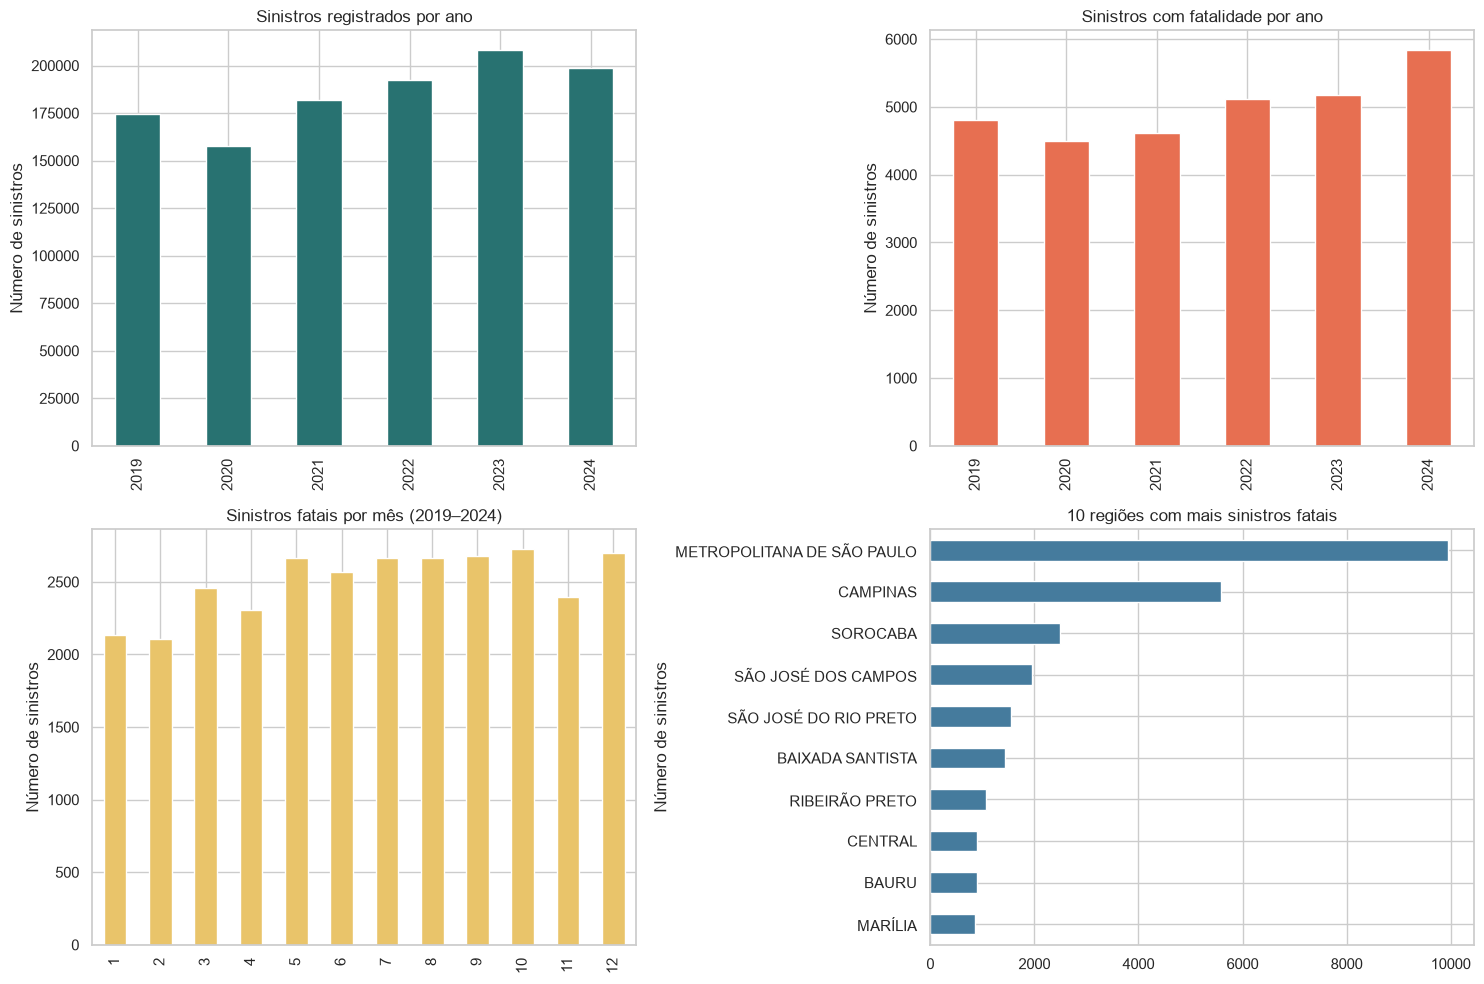

Vítimas com gravidade FATAL em sinistros de 2019 a 2024: 31,976
Vítimas fatais por modo de transporte:


,vitimas
modo_transporte_vitima,
MOTOCICLETA,12725
AUTOMOVEL,7657
PEDESTRE,7321
BICICLETA,2206
CAMINHAO,1161
NAO DISPONIVEL,519
ONIBUS,260
OUTROS,127


Vítimas fatais por sexo:


,vitimas
sexo,
MASCULINO,26423
FEMININO,5446
NAO DISPONIVEL,107


Vítimas fatais por faixa etária:


,vitimas
faixa_etaria_demografica,
20 a 24,3983
25 a 29,3252
30 a 34,2921
35 a 39,2913
40 a 44,2818
45 a 49,2384
50 a 54,2071
55 a 59,1951
NAO DISPONIVEL,1776


In [5]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from IPython.display import display

PASTA_DADOS = Path("dados_infosiga")
ARQUIVO_CACHE = PASTA_DADOS / "sinistros_analise_2019_2024.parquet"

colunas_sinistros = [
    "id_sinistro", "data_sinistro", "hora_sinistro", "dia_da_semana", "turno",
    "tipo_via", "tipo_local", "regiao_administrativa", "tp_sinistro_primario",
    "qtd_gravidade_fatal",
]
arquivos_sinistros = [
    PASTA_DADOS / "sinistros_2015-2021.csv",
    PASTA_DADOS / "sinistros_2022-2024.csv",
]

if ARQUIVO_CACHE.exists():
    sinistros_eda = pd.read_parquet(ARQUIVO_CACHE)
else:
    partes = [
        pd.read_csv(
            arquivo,
            sep=";",
            encoding="latin-1",
            usecols=lambda coluna: coluna in colunas_sinistros,
            low_memory=False,
        )
        for arquivo in arquivos_sinistros
    ]
    sinistros_eda = pd.concat(partes, ignore_index=True)
    sinistros_eda["data_sinistro"] = pd.to_datetime(
        sinistros_eda["data_sinistro"], format="%d/%m/%Y", errors="coerce"
    )
    sinistros_eda = sinistros_eda[
        sinistros_eda["data_sinistro"].dt.year.between(2019, 2024)
    ].copy()
    sinistros_eda["fatal"] = (
        pd.to_numeric(sinistros_eda["qtd_gravidade_fatal"], errors="coerce")
        .fillna(0)
        .gt(0)
        .astype("int8")
    )
    sinistros_eda["ano"] = sinistros_eda["data_sinistro"].dt.year
    sinistros_eda["mes"] = sinistros_eda["data_sinistro"].dt.month
    sinistros_eda.to_parquet(ARQUIVO_CACHE, index=False, compression="zstd")

print(f"Sinistros no recorte: {len(sinistros_eda):,}")
print(f"Período: {sinistros_eda['data_sinistro'].min():%d/%m/%Y} a {sinistros_eda['data_sinistro'].max():%d/%m/%Y}")
print(f"IDs duplicados: {sinistros_eda['id_sinistro'].duplicated().sum():,}")

resumo_anual = sinistros_eda.groupby("ano").agg(
    sinistros=("id_sinistro", "size"),
    fatais=("fatal", "sum"),
    proporcao_fatal=("fatal", "mean"),
)
resumo_anual["proporcao_fatal"] = resumo_anual["proporcao_fatal"].map(lambda valor: f"{valor:.2%}")
display(resumo_anual)

colunas_qualidade = [
    coluna for coluna in colunas_sinistros
    if coluna in sinistros_eda.columns and coluna != "qtd_gravidade_fatal"
]
qualidade = pd.DataFrame({
    "ausentes": sinistros_eda[colunas_qualidade].isna().sum(),
    "ausentes_%": (sinistros_eda[colunas_qualidade].isna().mean() * 100).round(2),
})
display(qualidade.sort_values("ausentes_%", ascending=False))

sns.set_theme(style="whitegrid")
fig, eixos = plt.subplots(2, 2, figsize=(15, 10))
resumo_anual["sinistros"].plot(kind="bar", ax=eixos[0, 0], color="#287271", title="Sinistros registrados por ano")
resumo_anual["fatais"].plot(kind="bar", ax=eixos[0, 1], color="#e76f51", title="Sinistros com fatalidade por ano")
sinistros_eda.groupby("mes")["fatal"].sum().reindex(range(1, 13)).plot(
    kind="bar", ax=eixos[1, 0], color="#e9c46a", title="Sinistros fatais por mês (2019–2024)"
)
(
    sinistros_eda.loc[sinistros_eda["fatal"].eq(1), "regiao_administrativa"]
    .fillna("NAO DISPONIVEL").value_counts().head(10).sort_values()
    .plot(kind="barh", ax=eixos[1, 1], color="#457b9d", title="10 regiões com mais sinistros fatais")
)
for eixo in eixos.flat:
    eixo.set_xlabel("")
    eixo.set_ylabel("Número de sinistros")
plt.tight_layout()
plt.show()

colunas_pessoas = [
    "ano_sinistro", "gravidade_lesao", "modo_transporte_vitima", "sexo",
    "faixa_etaria_demografica",
]
arquivos_pessoas = [
    PASTA_DADOS / "pessoas_2015-2021.csv",
    PASTA_DADOS / "pessoas_2022-2024.csv",
]
partes_pessoas = [
    pd.read_csv(
        arquivo, sep=";", encoding="latin-1",
        usecols=lambda coluna: coluna in colunas_pessoas, low_memory=False,
    )
    for arquivo in arquivos_pessoas
]
pessoas = pd.concat(partes_pessoas, ignore_index=True)
pessoas["ano_sinistro"] = pd.to_numeric(pessoas["ano_sinistro"], errors="coerce")
pessoas = pessoas[pessoas["ano_sinistro"].between(2019, 2024)]
fatais = pessoas[pessoas["gravidade_lesao"].astype("string").str.strip().str.upper().eq("FATAL")]
print(f"Vítimas com gravidade FATAL em sinistros de 2019 a 2024: {len(fatais):,}")
print("Vítimas fatais por modo de transporte:")
display(fatais["modo_transporte_vitima"].fillna("NAO DISPONIVEL").value_counts().head(12).to_frame("vitimas"))
print("Vítimas fatais por sexo:")
display(fatais["sexo"].fillna("NAO DISPONIVEL").value_counts().to_frame("vitimas"))
print("Vítimas fatais por faixa etária:")
display(fatais["faixa_etaria_demografica"].fillna("NAO DISPONIVEL").value_counts().head(12).to_frame("vitimas"))

# **Modelos**

## Modelo base de classificação

O baseline é uma regressão logística binária com peso balanceado por classe, aplicada a uma linha por sinistro. A divisão respeita o tempo: dados de 2019 a 2023 para treino e 2024 como teste final. Assim, o teste representa a capacidade de generalização para um período posterior, e não uma amostra aleatória do mesmo período. O ano de 2024 foi escolhido por estar completo na extração usada.

As variáveis explicativas são tipo primário do sinistro, tipo de via, tipo de local, região administrativa, dia da semana, turno e hora inteira extraída do campo `HH:MM`. Categorias ausentes e `NAO DISPONIVEL` são agrupadas como `NAO INFORMADO`; a imputação e a codificação one-hot são ajustadas somente nos dados de treino, por meio de um pipeline. Valores de hora ausentes (0,14% no recorte) são imputados pela mediana do treino. Identificadores, campos de gravidade, tipo de registro e contagens que definem o desfecho não são usados como preditores, reduzindo risco de vazamento.

Como a prevalência fatal é baixa, a acurácia não é a métrica principal. São reportados Average Precision (área sob a curva precisão-revocação), ROC-AUC, revocação e F1 no limiar padrão de 0,5, além da prevalência que serve como referência de Average Precision para um ranking sem discriminação. O limiar padrão não é necessariamente adequado à operação; sua seleção deve ser feita com validação temporal dentro do conjunto de treino, conforme o custo relativo de falsos negativos e falsos positivos. A regressão logística é uma linha de base interpretável, não uma ferramenta validada para decisão operacional ou causalidade.

# **Resultados**

As células seguintes treinam o modelo, imprimem as métricas no teste de 2024 e exibem os maiores coeficientes em razões de chance. Os coeficientes são condicionais às categorias de referência do one-hot e descrevem associações no modelo; não devem ser interpretados como efeitos causais.

In [6]:
import numpy as np
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    average_precision_score,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

colunas_categoricas = [
    "tp_sinistro_primario", "tipo_via", "tipo_local",
    "regiao_administrativa", "dia_da_semana", "turno",
]
base_modelo = sinistros_eda.copy()
base_modelo["hora"] = pd.to_numeric(
    base_modelo["hora_sinistro"].astype("string").str.split(":").str[0],
    errors="coerce",
)

for coluna in colunas_categoricas:
    base_modelo[coluna] = (
        base_modelo[coluna].astype("string").str.strip().str.upper()
        .replace({"": pd.NA, "NAO DISPONIVEL": pd.NA, "NÃO DISPONÍVEL": pd.NA})
        .fillna("NAO INFORMADO")
    )

colunas_numericas = ["hora"]
colunas_modelo = colunas_categoricas + colunas_numericas
treino = base_modelo[base_modelo["ano"] <= 2023]
teste = base_modelo[base_modelo["ano"] == 2024]
X_treino, y_treino = treino[colunas_modelo], treino["fatal"]
X_teste, y_teste = teste[colunas_modelo], teste["fatal"]

preprocessador = ColumnTransformer(
    transformers=[
        (
            "categoricas",
            Pipeline([
                ("imputacao", SimpleImputer(strategy="most_frequent")),
                ("onehot", OneHotEncoder(handle_unknown="ignore", min_frequency=50)),
            ]),
            colunas_categoricas,
        ),
        ("numericas", SimpleImputer(strategy="median"), colunas_numericas),
    ],
    remainder="drop",
)
modelo_base = Pipeline([
    ("preprocessamento", preprocessador),
    ("classificador", LogisticRegression(
        class_weight="balanced", max_iter=150, solver="liblinear", random_state=42
    )),
])
modelo_base.fit(X_treino, y_treino)
probabilidades = modelo_base.predict_proba(X_teste)[:, 1]
predicoes = (probabilidades >= 0.5).astype("int8")

metricas_baseline = pd.Series({
    "Sinistros no treino (2019–2023)": len(treino),
    "Sinistros no teste (2024)": len(teste),
    "Prevalência fatal no teste": y_teste.mean(),
    "Average Precision (AUC-PR)": average_precision_score(y_teste, probabilidades),
    "ROC-AUC": roc_auc_score(y_teste, probabilidades),
    "Precisão (limiar 0,5)": precision_score(y_teste, predicoes, zero_division=0),
    "Revocação (limiar 0,5)": recall_score(y_teste, predicoes, zero_division=0),
    "F1 (limiar 0,5)": f1_score(y_teste, predicoes, zero_division=0),
    "AP de referência (prevalência)": y_teste.mean(),
})
display(metricas_baseline.to_frame("resultado").style.format("{:.4f}"))

print("Matriz de confusão (linhas: real; colunas: previsto; limiar = 0,5):")
display(pd.DataFrame(
    confusion_matrix(y_teste, predicoes),
    index=["Real não fatal", "Real fatal"],
    columns=["Previsto não fatal", "Previsto fatal"],
))

nomes_features = modelo_base.named_steps["preprocessamento"].get_feature_names_out()
coeficientes = modelo_base.named_steps["classificador"].coef_[0]
tabela_coeficientes = pd.DataFrame({
    "atributo": nomes_features,
    "coeficiente": coeficientes,
})
tabela_coeficientes["razao_de_chance"] = np.exp(tabela_coeficientes["coeficiente"])
print("Associações positivas mais fortes (referência: demais categorias e atributos constantes):")
display(tabela_coeficientes.nlargest(10, "coeficiente").reset_index(drop=True).round(3))
print("Associações negativas mais fortes:")
display(tabela_coeficientes.nsmallest(10, "coeficiente").reset_index(drop=True).round(3))

,resultado
Sinistros no treino (2019–2023),914543.0000
Sinistros no teste (2024),198688.0000
Prevalência fatal no teste,0.0294
Average Precision (AUC-PR),0.2291
ROC-AUC,0.8710
"Precisão (limiar 0,5)",0.0995
"Revocação (limiar 0,5)",0.8047
"F1 (limiar 0,5)",0.1771
AP de referência (prevalência),0.0294


Matriz de confusão (linhas: real; colunas: previsto; limiar = 0,5):


,Previsto não fatal,Previsto fatal
Real não fatal,150364,42488
Real fatal,1140,4696


Associações positivas mais fortes (referência: demais categorias e atributos constantes):


,atributo,coeficiente,razao_de_chance
0,categoricas__turno_NAO INFORMADO,7.182,1315.236
1,categoricas__tipo_via_NAO INFORMADO,4.684,108.216
2,categoricas__tp_sinistro_primario_ATROPELAMENTO,2.156,8.639
3,categoricas__tipo_local_PUBLICO,2.129,8.410
4,categoricas__tipo_local_PRIVADO,2.070,7.924
5,categoricas__tp_sinistro_primario_CHOQUE,1.699,5.467
6,categoricas__tp_sinistro_primario_OUTROS,0.912,2.489
7,categoricas__regiao_administrativa_REGISTRO,0.736,2.087
8,categoricas__tp_sinistro_primario_COLISAO,0.652,1.919
9,categoricas__dia_da_semana_DOMINGO,0.409,1.505


Associações negativas mais fortes:


,atributo,coeficiente,razao_de_chance
0,categoricas__tp_sinistro_primario_NAO INFORMADO,-4.755,0.009
1,categoricas__tipo_local_NAO INFORMADO,-3.535,0.029
2,categoricas__tipo_via_VIAS URBANAS,-2.704,0.067
3,categoricas__turno_TARDE,-2.151,0.116
4,categoricas__turno_NOITE,-1.886,0.152
5,categoricas__turno_MANHA,-1.876,0.153
6,categoricas__tipo_via_ESTRADAS E RODOVIAS,-1.315,0.268
7,categoricas__turno_MADRUGADA,-0.604,0.547
8,categoricas__regiao_administrativa_MARÍLIA,-0.300,0.741
9,categoricas__regiao_administrativa_PRESIDENTE ...,-0.237,0.789


# **Resultados**

## Exploração

No recorte de 2019 a 2024 foram encontrados 1.113.231 sinistros, sem IDs duplicados. A proporção fatal variou de 2,49% (2023) a 2,94% (2024); o total de ocorrências fatais no conjunto de sinistros aumentou de 4.804 em 2019 para 5.836 em 2024. Como a base registra revisões e as contagens não têm denominadores de exposição, essas diferenças descrevem os registros observados e não isolam mudanças de risco.

A análise da tabela de pessoas identificou 31.976 registros com gravidade `FATAL` em sinistros de 2019–2024; motocicleta (12.725), automóvel (7.657) e pedestre (7.321) são os modos mais frequentes entre esses registros. A contagem de vítimas não equivale à contagem de sinistros fatais: um sinistro pode produzir mais de uma vítima. Entre as vítimas com sexo informado, predominam registros masculinos (26.423 contra 5.446 femininos). A faixa de 20 a 24 anos é a mais frequente (3.983). Esses valores são frequências absolutas e não taxas por pessoa exposta.

## Regressão logística: teste temporal de 2024

O treino contém 914.543 sinistros de 2019–2023 e o teste 198.688 sinistros de 2024. A prevalência fatal no teste foi 2,94%. A Average Precision foi 0,2291, aproximadamente 7,8 vezes a referência de prevalência (0,0294), e a ROC-AUC foi 0,8710. No limiar inicial de 0,5, a revocação foi 0,8047, a precisão 0,0995 e o F1 0,1771. O modelo encontrou 4.696 dos 5.836 sinistros fatais, mas classificou 42.488 sinistros não fatais como fatais. Isso é um ponto de partida com bom foco em recuperar a classe minoritária, mas a precisão baixa torna o limiar inadequado sem uma análise de custos e ajuste em validação temporal.

As razões de chance mais elevadas incluem `tipo_local_PUBLICO` e categorias como atropelamento e choque. Entretanto, categorias `NAO INFORMADO` também aparecem entre os maiores coeficientes: isso evidencia que ausência e processo de classificação podem estar associados ao desfecho no conjunto, e requer investigação antes de interpretação substantiva. Os coeficientes são associações do modelo, dependem da categoria de referência e não indicam causalidade. O resultado é preliminar; a comparação com árvores, o ajuste de limiar, a calibração e o ramo de séries temporais ficam para a próxima etapa.

# **Dicussão e Conclusão**

Conclusões; análise crítica dos resultados do trabalho (suas qualidades e limitações); alcance do objetivo inicial (a solução do problema); potenciais melhorias no projeto.

# **Apresentação**

Colocar os links do vídeo (apresentação com apoio de slides).

# **Referências**

AGÊNCIA BRASIL. Capital paulista tem 2º maior número de mortes no trânsito em 2025. Brasília, 25 jan. 2026. Disponível em: https://agenciabrasil.ebc.com.br/geral/noticia/2026-01/capital-paulista-tem-2o-maior-numero-de-mortes-no-transito-em-2025. Acesso em: 31 ago. 2026.

BREIMAN, Leo. Random forests. **Machine Learning**, v. 45, n. 1, p. 5-32, 2001.

CHANG, Li-Yen; WANG, Hsiu-Wen. Analysis of traffic injury severity: an application of non-parametric classification tree techniques. **Accident Analysis & Prevention**, v. 38, n. 5, p. 1019-1027, 2006. DOI: https://doi.org/10.1016/j.aap.2006.04.009.

CHEN, Tianqi; GUESTRIN, Carlos. XGBoost: a scalable tree boosting system. In: ACM SIGKDD INTERNATIONAL CONFERENCE ON KNOWLEDGE DISCOVERY AND DATA MINING, 22., 2016, San Francisco. **Proceedings** [...]. New York: ACM, 2016. p. 785-794.

HASTIE, Trevor; TIBSHIRANI, Robert; FRIEDMAN, Jerome. **The elements of statistical learning**: data mining, inference, and prediction. 2. ed. New York: Springer, 2009.

HYNDMAN, Rob J.; ATHANASOPOULOS, George. **Forecasting**: principles and practice. 3. ed. Melbourne: OTexts, 2021. Disponível em: https://otexts.com/fpp3/. Acesso em: 28 set. 2026.

IRANITALAB, Amirfarrokh; KHATTAK, Aemal J. Comparison of four statistical and machine learning methods for crash severity prediction. **Accident Analysis & Prevention**, v. 108, p. 27-36, 2017. DOI: https://doi.org/10.1016/j.aap.2017.08.008.

JEONG, Heejin; JANG, Youngchan; BOWMAN, Patrick J.; MASOUD, Neda. Classification of motor vehicle crash injury severity: a hybrid approach for imbalanced data. **Accident Analysis & Prevention**, v. 120, p. 250-261, 2018. DOI: https://doi.org/10.1016/j.aap.2018.08.025.

LUNDBERG, Scott M.; LEE, Su-In. A unified approach to interpreting model predictions. In: CONFERENCE ON NEURAL INFORMATION PROCESSING SYSTEMS, 31., 2017, Long Beach. **Advances in Neural Information Processing Systems**. Long Beach: NeurIPS, 2017. p. 4765-4774.

MOBILIDADE SAMPA. Governo de SP lança Infosiga 3.0. São Paulo, 19 set. 2025. Disponível em: https://mobilidadesampa.com.br/2025/09/infosiga-3-0-dados-transito/. Acesso em: 31 ago. 2026.

SÃO PAULO (Estado). Departamento Estadual de Trânsito. **Sinistros (Infosiga)**. São Paulo: Portal de Dados Abertos do Estado de São Paulo, 2026. Disponível em: https://dadosabertos.sp.gov.br/dataset/sinistros-infosiga. Acesso em: 31 ago. 2026.

SOLTANI, Ali; AFSHARI, Saeid; AMIRI, Mohammad Amin. Time-series projecting road traffic fatalities in Australia: insights for targeted safety interventions. **Injury**, v. 56, n. 3, art. 112166, 2025. DOI: https://doi.org/10.1016/j.injury.2025.112166.

TAYLOR, Sean J.; LETHAM, Benjamin. Forecasting at scale. **The American Statistician**, v. 72, n. 1, p. 37-45, 2018.

WIRTH, Rüdiger; HIPP, Jochen. CRISP-DM: towards a standard process model for data mining. In: INTERNATIONAL CONFERENCE ON THE PRACTICAL APPLICATIONS OF KNOWLEDGE DISCOVERY AND DATA MINING, 4., 2000, Manchester. **Proceedings** [...]. Manchester: Practical Application Company, 2000. p. 29-39.

WORLD HEALTH ORGANIZATION. **Global status report on road safety 2023**. Genebra: World Health Organization, 2023.